# Data Understanding: Rain in Australia
**UTS Data Science 2026/2027**

- Sumber dataset: [Kaggle / Rain in Australia](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package).
- Asal pengamatan: Australian Bureau of Meteorology.
- File yang diperiksa: `weatherAUS.csv` milik kelompok (145.460 baris × 23 kolom).
- Notebook ini hanya memeriksa Data Understanding; belum mengubah data atau melatih model.
- Grafik hubungan fitur dengan label memakai periode eksplorasi historis; periode lebih baru disisihkan sebagai rancangan holdout untuk mencegah pengambilan keputusan berbasis label test.

## Sumber dan lisensi data

**Sumber dokumentasi:** [Kaggle](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package) 

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
source_paths = [Path("data/weatherAUS.csv"), Path("weatherAUS.csv")]
path = next((p for p in source_paths if p.is_file()), None)
if path is None:
    raise FileNotFoundError("File weatherAUS.csv belum ditemukan. Unduh dari Kaggle dan simpan di folder notebook atau data/weatherAUS.csv.")
df = pd.read_csv(path, low_memory=False)
print("Sumber file:", path.resolve())
print("Ukuran dataset:", df.shape)
display(df.head())

Sumber file: D:\Lahar V2\Project\Project Akhir Data Science\weatherAUS.csv
Ukuran dataset: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## Struktur dataset dan validasi skema
Periksa apakah format CSV sesuai versi `weatherAUS` yang dipilih. `RISK_MM` pada beberapa versi mengandung informasi hujan besok dan tidak boleh digunakan sebagai fitur prediksi.

In [2]:
expected_cols = ["Date", "Location", "MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine", 
                 "WindGustDir", "WindGustSpeed", "WindDir9am", "WindDir3pm", "WindSpeed9am", 
                 "WindSpeed3pm", "Humidity9am", "Humidity3pm", "Pressure9am", "Pressure3pm", 
                 "Cloud9am", "Cloud3pm", "Temp9am", "Temp3pm", "RainToday", "RainTomorrow"]
print("Kolom yang tidak ditemukan:", sorted(set(expected_cols) - set(df.columns)))
print("Kolom tambahan:", sorted(set(df.columns) - set(expected_cols)))
if "RISK_MM" in df.columns:
    print("PERINGATAN: RISK_MM adalah target leakage, JANGAN gunakan sebagai fitur model.")
print("Jenis data")
display(df.dtypes.rename("dtype").to_frame())
print("Statistik numerik")
display(df.describe().T)

Kolom yang tidak ditemukan: []
Kolom tambahan: []
Jenis data


,dtype
Date,str
Location,str
MinTemp,float64
MaxTemp,float64
Rainfall,float64
Evaporation,float64
Sunshine,float64
WindGustDir,str
WindGustSpeed,float64
WindDir9am,str


Statistik numerik


,count,mean,std,min,25%,50%,75%,max
MinTemp,143975.0,12.194034,6.398495,-8.5,7.6,12.0,16.9,33.9
MaxTemp,144199.0,23.221348,7.119049,-4.8,17.9,22.6,28.2,48.1
Rainfall,142199.0,2.360918,8.478060,0.0,0.0,0.0,0.8,371.0
Evaporation,82670.0,5.468232,4.193704,0.0,2.6,4.8,7.4,145.0
Sunshine,75625.0,7.611178,3.785483,0.0,4.8,8.4,10.6,14.5
WindGustSpeed,135197.0,40.035230,13.607062,6.0,31.0,39.0,48.0,135.0
WindSpeed9am,143693.0,14.043426,8.915375,0.0,7.0,13.0,19.0,130.0
WindSpeed3pm,142398.0,18.662657,8.809800,0.0,13.0,19.0,24.0,87.0
Humidity9am,142806.0,68.880831,19.029164,0.0,57.0,70.0,83.0,100.0
Humidity3pm,140953.0,51.539116,20.795902,0.0,37.0,52.0,66.0,100.0


## Kualitas data: missing value
Pada file ini terdapat **343.248 sel kosong**; **89.040 baris (61,21%)** memiliki minimal satu nilai kosong. Empat fitur dengan persentase tertinggi: `Sunshine` **48,01%**, `Evaporation` **43,17%**, `Cloud3pm` **40,81%**, `Cloud9am` **38,42%**. Target `RainTomorrow` kosong pada **3.267 baris (2,25%)**.

,Jumlah_Hilang,Persentase_Hilang
Sunshine,69835,48.01
Evaporation,62790,43.17
Cloud3pm,59358,40.81
Cloud9am,55888,38.42
Pressure9am,15065,10.36
Pressure3pm,15028,10.33
WindDir9am,10566,7.26
WindGustDir,10326,7.10
WindGustSpeed,10263,7.06
Humidity3pm,4507,3.10


Jumlah sel kosong total: 343248
Jumlah target RainTomorrow kosong: 3267


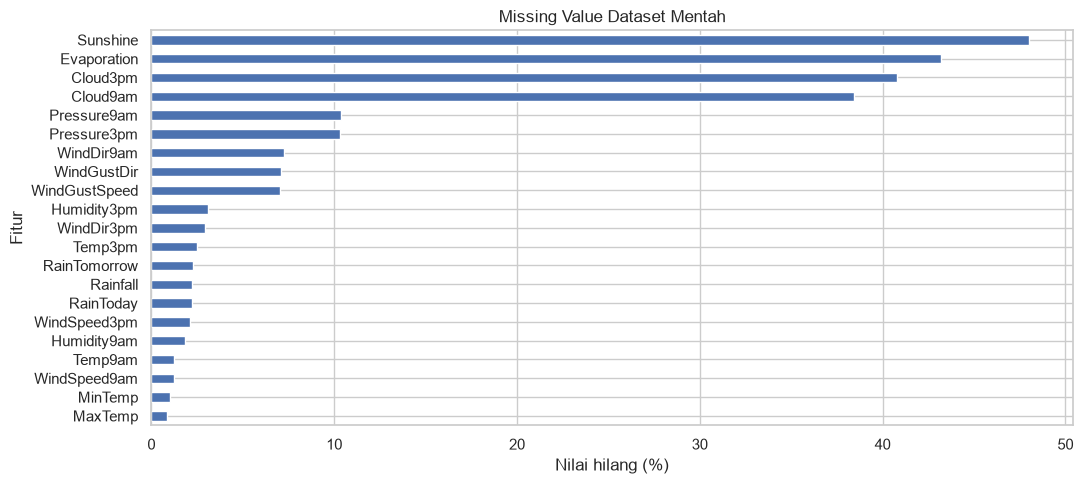

In [3]:
missing = pd.DataFrame({
    "Jumlah_Hilang": df.isna().sum(),
    "Persentase_Hilang": (df.isna().mean()*100).round(2)
}).sort_values("Jumlah_Hilang", ascending=False)
display(missing)
print("Jumlah sel kosong total:", int(df.isna().sum().sum()))
print("Jumlah target RainTomorrow kosong:", int(df["RainTomorrow"].isna().sum()))
fig, ax = plt.subplots(figsize=(11,5))
missing.query("Jumlah_Hilang > 0").sort_values("Persentase_Hilang")["Persentase_Hilang"].plot.barh(ax=ax)
ax.set(xlabel="Nilai hilang (%)", ylabel="Fitur", title="Missing Value Dataset Mentah")
plt.tight_layout(); plt.show()

## Kualitas data: duplikasi, pemeriksaan rentang, dan outlier
CSV ini memiliki **0 duplikat baris identik** dan **0 duplikat gabungan Date–Location**. IQR mendeteksi nilai ekstrem pada beberapa variabel, misalnya `Rainfall` **25.578 pengamatan** (17,58% seluruh baris). Karena hujan harian banyak bernilai 0, batas IQR bukan alasan menghapus data hujan ekstrem secara otomatis.

**Catatan okta:** Angka `9` pada laporan tutupan awan dapat berarti **langit tertutup fenomena lain seperti kabut** (bukan sekadar 9/8 tutupan awan), sehingga angka ini jangan langsung dianggap kesalahan. Lihat definisi okta pada sumber meteorologi dan validasi kembali kode yang digunakan oleh penyedia data.

In [4]:
print("Duplikat seluruh kolom:", int(df.duplicated().sum()))
if {"Date", "Location"}.issubset(df.columns):
    print("Duplikat kombinasi Date & Location:", int(df.duplicated(subset=["Date", "Location"]).sum()))
checks = {}
for k in ["Humidity9am", "Humidity3pm"]:
    if k in df: checks[k + " di luar 0–100%"] = int(((df[k] < 0)|(df[k] > 100)).sum())
for k in ["Cloud9am", "Cloud3pm"]:
    if k in df: checks[k + " di luar 0–9 (9 dapat berarti langit tertutup fenomena lain)"] = int(((df[k] < 0)|(df[k] > 9)).sum())
for k in ["Rainfall", "Evaporation", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]:
    if k in df: checks[k + " bernilai negatif"] = int((df[k] < 0).sum())
print("Validasi sederhana rentang nilai:");display(pd.Series(checks, name="Jumlah_Nilai_Tidak_Valid").to_frame())
numeric_cols = df.select_dtypes(include="number").columns.drop("RISK_MM", errors="ignore")
outliers=[]
for k in numeric_cols:
    s = df[k].dropna()
    q1,q3 = s.quantile([.25,.75]);iqr=q3-q1
    n=int(((s < q1-1.5*iqr)|(s > q3+1.5*iqr)).sum())
    outliers.append((k,n,round(100*n/max(len(s),1),2)))
outliers_df=pd.DataFrame(outliers, columns=["Kolom", "Jumlah_Di_Luar_IQR", "Persen_NonMissing"]).sort_values("Jumlah_Di_Luar_IQR", ascending=False)
display(outliers_df)


Duplikat seluruh kolom: 0
Duplikat kombinasi Date & Location: 0
Validasi sederhana rentang nilai:


,Jumlah_Nilai_Tidak_Valid
Humidity9am di luar 0–100%,0
Humidity3pm di luar 0–100%,0
Cloud9am di luar 0–9 (9 dapat berarti langit tertutup fenomena lain),0
Cloud3pm di luar 0–9 (9 dapat berarti langit tertutup fenomena lain),0
Rainfall bernilai negatif,0
Evaporation bernilai negatif,0
WindGustSpeed bernilai negatif,0
WindSpeed9am bernilai negatif,0
WindSpeed3pm bernilai negatif,0


,Kolom,Jumlah_Di_Luar_IQR,Persen_NonMissing
2,Rainfall,25578,17.99
5,WindGustSpeed,3092,2.29
7,WindSpeed3pm,2523,1.77
3,Evaporation,1995,2.41
6,WindSpeed9am,1817,1.26
8,Humidity9am,1425,1.00
10,Pressure9am,1191,0.91
11,Pressure3pm,919,0.70
15,Temp3pm,764,0.54
1,MaxTemp,489,0.34


## Lokasi serta periode pengamatan
Pada file ini terdapat **49 lokasi** dengan rentang tanggal **1 November 2007–25 Juni 2017** dan **3.436 tanggal unik**. Jumlah pencatatan antarstasiun berbeda: `Canberra` **3.436**, `Sydney` **3.344**, tetapi `Uluru`, `Nhil`, dan `Katherine` masing-masing **1.578** baris.

Ini menunjukkan potensi bias cakupan lokasi dan periode, sehingga hasil bukan jaminan akurat untuk semua wilayah/iklim.

Tanggal paling awal: 2007-11-01 00:00:00
Tanggal paling akhir: 2017-06-25 00:00:00
Tanggal tidak valid: 0
Jumlah lokasi unik: 49
10 lokasi dengan observasi terbanyak:


,Jumlah_Pengamatan
Location,
Canberra,3436
Sydney,3344
Melbourne,3193
Brisbane,3193
Adelaide,3193
Perth,3193
Hobart,3193
Darwin,3193
Albury,3040


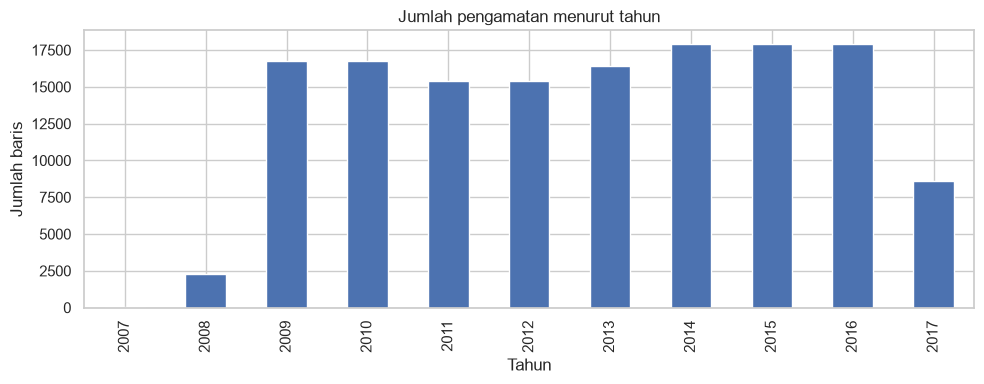

In [5]:
date_parsed = pd.to_datetime(df["Date"], errors="coerce")
print("Tanggal paling awal:", date_parsed.min())
print("Tanggal paling akhir:", date_parsed.max())
print("Tanggal tidak valid:", int(date_parsed.isna().sum()))
print("Jumlah lokasi unik:", df["Location"].nunique(dropna=True))
print("10 lokasi dengan observasi terbanyak:")
display(df["Location"].value_counts().head(10).rename("Jumlah_Pengamatan").to_frame())
year_counts = date_parsed.dt.year.value_counts().sort_index()
fig, ax=plt.subplots(figsize=(10,4))
year_counts.plot(kind="bar", ax=ax)
ax.set(title="Jumlah pengamatan menurut tahun", xlabel="Tahun", ylabel="Jumlah baris")
plt.tight_layout();plt.show()

## Rancangan pembagian kronologis untuk EDA
Untuk mengurangi risiko data leakage, kita menjadikan 8 Agustus 2015 sebagai batas hasil pemilahan 80% tanggal unik yang lebih awal. Periode EDA memakai baris berlabel valid sebelum tanggal tersebut (**109.302 baris**); periode berikutnya disisihkan sebagai kandidat pengujian (**32.891 baris berlabel valid**). Pembagian ini adalah rancangan awal dan akan dibakukan bersama pemodelan.

In [6]:
work = df.copy()
work["Date"] = pd.to_datetime(work["Date"], errors="coerce")
valid_dates = pd.Series(work["Date"].dropna().unique()).sort_values().reset_index(drop=True)
if len(valid_dates) < 10:
    raise ValueError("Data tanggal valid terlalu sedikit untuk split kronologis.")
cutoff = valid_dates.iloc[int(len(valid_dates)*0.8)]
eda = work[(work["Date"] < cutoff) & (work["RainTomorrow"].isin(["Yes", "No"]))].copy()
heldout = work[work["Date"] >= cutoff].copy()
print("Tanggal pemisah periode evaluasi:", cutoff.date())
print("Baris untuk EDA eksplorasi (target valid):", len(eda))
print("Baris periode yang disisihkan untuk pengujian:", len(heldout))
print("Periode EDA:", eda["Date"].min(), "hingga", eda["Date"].max())


Tanggal pemisah periode evaluasi: 2015-08-08
Baris untuk EDA eksplorasi (target valid): 109302
Baris periode yang disisihkan untuk pengujian: 33711
Periode EDA: 2007-11-01 00:00:00 hingga 2015-08-07 00:00:00


## 3.5 EDA: distribusi RainTomorrow pada periode eksplorasi
Dalam periode eksplorasi dengan target valid, terdapat **84.636** pengamatan `No` dan **24.666** pengamatan `Yes`, menunjukkan kelas hujan lebih sedikit. Dalam keseluruhan CSV yang berlabel, kelas `Yes` berjumlah **31.877** dari **142.193** (**22,42%**), sementara `No` **77,58%**.

**Insight:** akurasi saja dapat menyesatkan; evaluasi perlu menekankan recall, precision, F1-score kelas `Yes`, dan confusion matrix.

Distribusi kelas:


,Jumlah,Persen
RainTomorrow,,
No,84636,77.43
Yes,24666,22.57


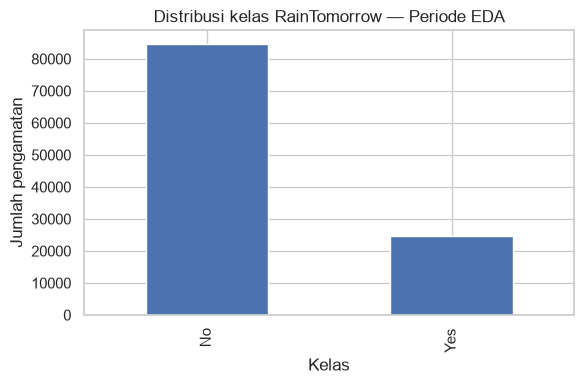

In [7]:
class_distribution = eda["RainTomorrow"].value_counts().reindex(["No", "Yes"], fill_value=0)
print("Distribusi kelas:")
display(pd.DataFrame({"Jumlah": class_distribution, "Persen":(class_distribution/class_distribution.sum()*100).round(2)}))
fig, ax=plt.subplots(figsize=(6,4))
class_distribution.plot.bar(ax=ax)
ax.set(title="Distribusi kelas RainTomorrow — Periode EDA", xlabel="Kelas", ylabel="Jumlah pengamatan")
plt.tight_layout();plt.show()

## EDA: kelembapan sore versus target (periode eksplorasi)
Kelembapan pukul 15.00 memiliki **median 70%** pada kelompok yang besok hujan dan **48%** pada kelompok yang tidak hujan, dihitung dari baris yang memiliki `Humidity3pm` dan target valid. Pola ini merupakan asosiasi, tidak membuktikan bahwa kelembapan secara tunggal menyebabkan hujan.

Pertanyaan penelitian: seberapa banyak kombinasi fitur lain dapat membantu memprediksi `RainTomorrow`?

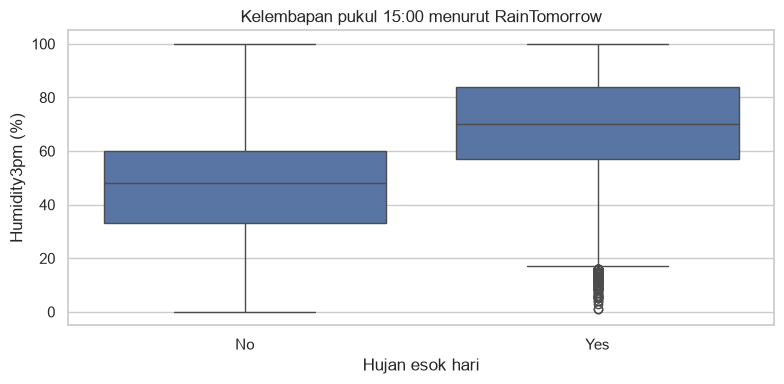

Ringkasan kelembapan pukul 15:00 menurut kelas target:


,count,mean,median,std
RainTomorrow,,,,
No,83676,46.61,48.0,18.43
Yes,24245,68.96,70.0,18.78


In [8]:
fig, ax=plt.subplots(figsize=(8,4))
sns.boxplot(data=eda, x="RainTomorrow", y="Humidity3pm", order=["No","Yes"], ax=ax)
ax.set(title="Kelembapan pukul 15:00 menurut RainTomorrow", xlabel="Hujan esok hari", ylabel="Humidity3pm (%)")
plt.tight_layout();plt.show()
print("Ringkasan kelembapan pukul 15:00 menurut kelas target:")
display(eda.groupby("RainTomorrow")["Humidity3pm"].agg(["count","mean","median","std"]).round(2))

## EDA: korelasi fitur numerik
Untuk gambaran awal, tekanan udara pagi dan sore saling berkorelasi sangat kuat (**r ≈ 0,96** pada keseluruhan CSV), demikian juga suhu 09.00 dan 15.00 (**r ≈ 0,86**). Korelasi tinggi dapat mengurangi informasi independen dari beberapa fitur dan penting dibahas saat menggunakan asumsi Naive Bayes.

Tidak gunakan `RISK_MM` karena pada beberapa versi dataset variabel itu mengukur jumlah hujan hari berikutnya dan akan menimbulkan target leakage. Korelasi bukan bukti sebab-akibat.

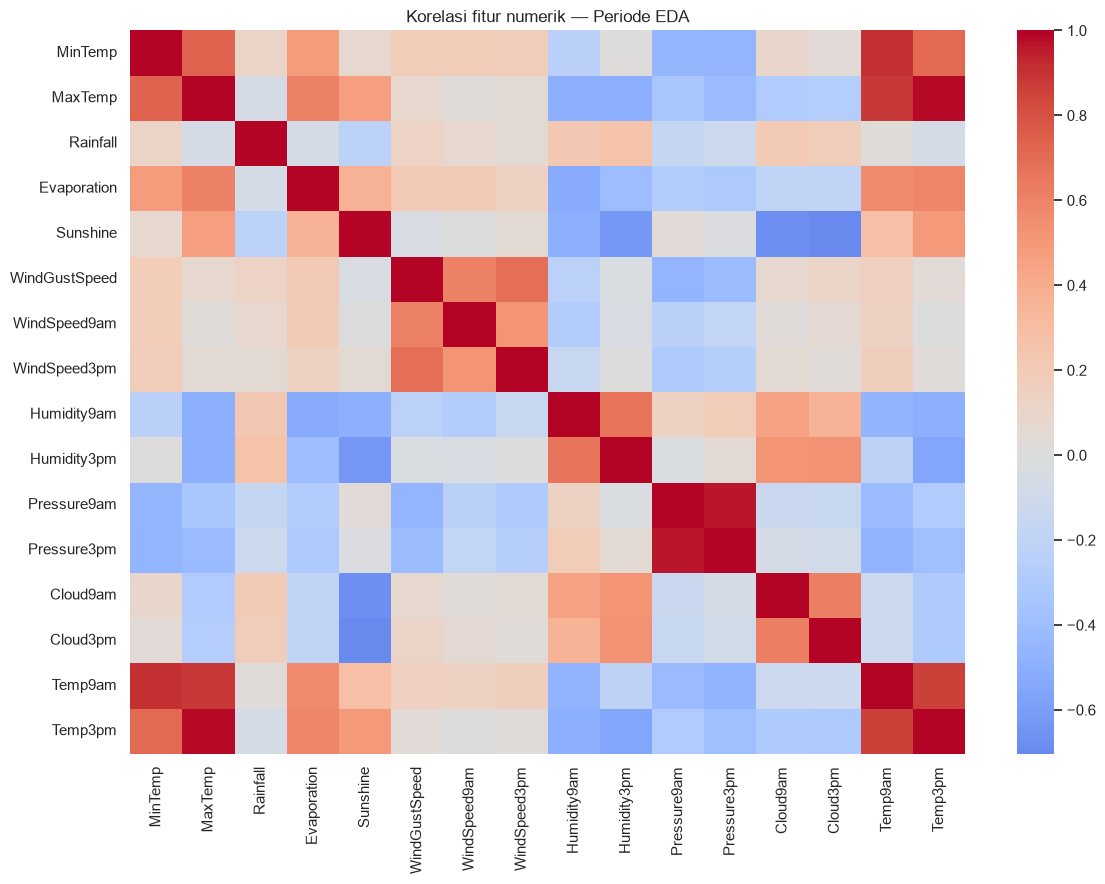

In [9]:
num_eda = eda.select_dtypes(include="number").drop(columns=["RISK_MM"], errors="ignore")
fig, ax=plt.subplots(figsize=(12,9))
sns.heatmap(num_eda.corr(numeric_only=True), cmap="coolwarm", center=0, ax=ax)
ax.set(title="Korelasi fitur numerik — Periode EDA")
plt.tight_layout();plt.show()

## EDA: proporsi kejadian hujan menurut lokasi (periode eksplorasi)
Perbedaan geografis sangat nyata dalam data: pada subset EDA, `Portland` memiliki sekitar **37,11%** label `Yes` (**2.312** pengamatan berlabel), sementara `Uluru` sekitar **6,52%** (**844** pengamatan). Perbandingan ini deskriptif, bukan bukti bahwa klasifikasi akan lebih akurat di satu kota.

Pola per lokasi dipengaruhi perbedaan iklim, musim, jumlah data, dan kelengkapan pencatatan.

Lokasi dengan persentase hujan relatif tinggi:


,jumlah,proporsi_hujan
Location,,
Portland,2312,37.11
Walpole,2155,33.23
Dartmoor,2257,32.34
Cairns,2348,31.39
MountGambier,2352,30.87
NorfolkIsland,2320,30.22
CoffsHarbour,2267,30.08
Witchcliffe,2278,29.94
Albany,2343,29.92


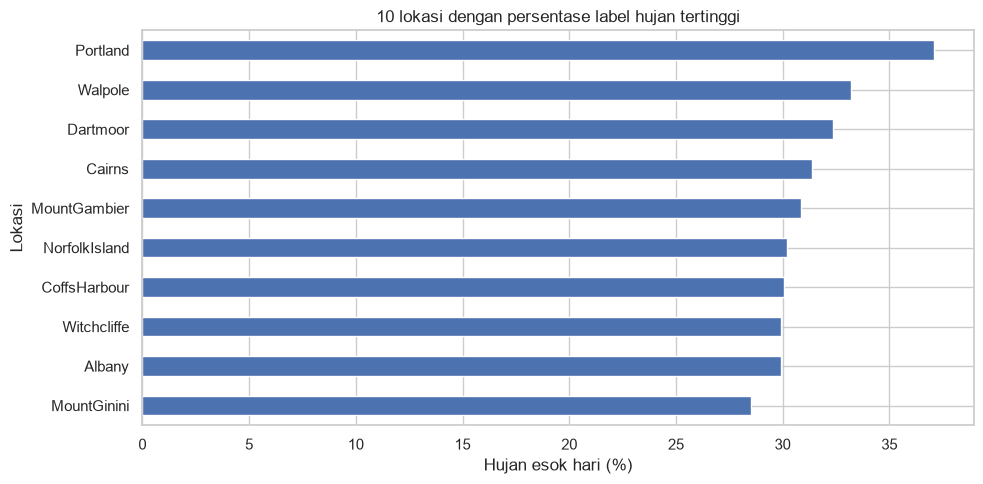

In [10]:
loc_stats = eda.groupby("Location")["RainTomorrow"].agg(jumlah="size", proporsi_hujan=lambda s: (s=="Yes").mean()*100)
loc_stats = loc_stats[loc_stats["jumlah"] >= 100].sort_values("proporsi_hujan", ascending=False)
print("Lokasi dengan persentase hujan relatif tinggi:")
display(loc_stats.head(10).round(2))
if len(loc_stats):
    fig, ax=plt.subplots(figsize=(10,5))
    loc_stats.head(10).sort_values("proporsi_hujan")["proporsi_hujan"].plot.barh(ax=ax)
    ax.set(title="10 lokasi dengan persentase label hujan tertinggi", xlabel="Hujan esok hari (%)", ylabel="Lokasi")
    plt.tight_layout();plt.show()

## Tambahan EDA: tekanan sore dan label hujan
Pada seluruh dataset berlabel, median `Pressure3pm` sekitar **1.012,2 hPa** pada kelompok `Yes` dan **1.016,0 hPa** pada kelompok `No`. Untuk menjaga periode pengujian, grafik dan angka eksperimen berikut dihitung ulang hanya pada data EDA historis.

,count,mean,median
RainTomorrow,,,
No,76506,1016.13,1016.0
Yes,22324,1012.40,1012.2


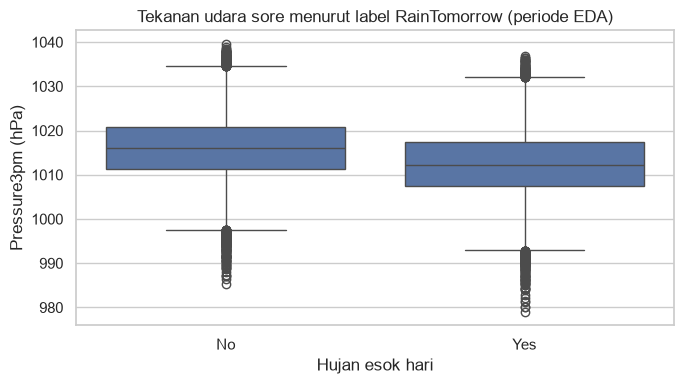

In [11]:
display(eda.groupby("RainTomorrow")["Pressure3pm"].agg(["count","mean","median"]).round(2))
fig, ax=plt.subplots(figsize=(7,4))
sns.boxplot(data=eda, x="RainTomorrow", y="Pressure3pm", order=["No", "Yes"], ax=ax)
ax.set(title="Tekanan udara sore menurut label RainTomorrow (periode EDA)", xlabel="Hujan esok hari", ylabel="Pressure3pm (hPa)")
plt.tight_layout(); plt.show()

## Tambahan EDA: pola musiman
Amati variasi proporsi kelas `Yes` per bulan (pada periode eksplorasi). Perbedaan ini mungkin dipengaruhi musim, lokasi, dan perbedaan jumlah pengamatan; karena itu jangan menganggap hasilnya sebagai pola universal seluruh Australia.

,jumlah,persen_hujan
Date,,
1,9978,18.24
2,7811,22.43
3,10091,20.61
4,8421,22.55
5,10048,22.91
6,9729,26.50
7,10268,26.30
8,9108,25.14
9,8492,21.87


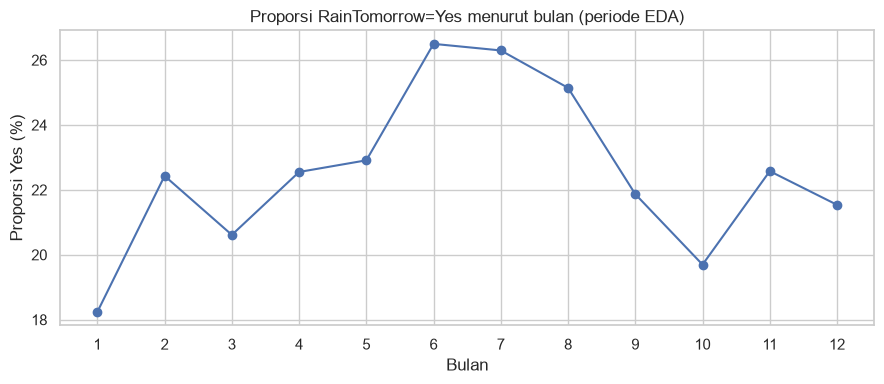

In [12]:
monthly=(eda.groupby(eda["Date"].dt.month)["RainTomorrow"]
         .agg(jumlah="size", persen_hujan=lambda s: 100*(s=="Yes").mean()))
display(monthly.round(2))
fig, ax=plt.subplots(figsize=(9,4))
monthly["persen_hujan"].plot(marker="o", ax=ax)
ax.set(title="Proporsi RainTomorrow=Yes menurut bulan (periode EDA)", xlabel="Bulan", ylabel="Proporsi Yes (%)", xticks=range(1,13))
plt.tight_layout();plt.show()

## Kesimpulan Data Understanding
1. Dataset yang diperiksa benar-benar memuat **145.460 × 23** data, **49** lokasi, periode 2007-11-01 s.d. 2017-06-25.
2. Terdapat **343.248 nilai hilang**; yang terbanyak adalah `Sunshine` (48,01%), `Evaporation` (43,17%), `Cloud3pm` (40,81%), dan `Cloud9am` (38,42%). Target kosong: **3.267**.
3. Tidak terdapat duplikat baris maupun pasangan tanggal-lokasi. Ada nilai yang ditandai outlier oleh IQR, terutama `Rainfall` (25.578), tetapi belum tentu kesalahan observasi.
4. Kelas positif `RainTomorrow=Yes` adalah **22,42%** dari label valid, sehingga ada ketidakseimbangan kelas.
5. Periode eksplorasi awal (sebelum 2015-08-08) menunjukkan median `Humidity3pm` lebih tinggi ketika besok hujan (**70%**) daripada tidak hujan (**48%**).
6. Keterwakilan berbeda antarwilayah dan tahun; pembagian kronologis dipilih sebagai rencana evaluasi yang lebih ketat.
7. Data Preparation berikutnya evaluasi missingness, imputasi menggunakan data pelatihan, encoding kategorikal, pemilihan fitur meteorologi, validasi waktu tersedianya fitur, lalu pelatihan GaussianNB dan RandomForestClassifier.
8. Batasan bukan prakiraan real-time; model tidak dapat langsung digunakan untuk wilayah Indonesia; lisensi redistribusi CSV lengkap harus dipastikan.